# Figure 2: perturbation-class coarse-state occupancy

This notebook creates the requested **perturbation-class occupancy bubble matrix** and the complete target-level supplementary heatmap from the processed CC-Perturb-seq H5AD on Sherlock.

It intentionally does **not** use target→program CRT effects, cNMF differential effects, or perturbation-driven clustering. State assignments are fixed before testing using the existing author-defined mapping of `leiden_res_0.5` recovered from `ipsc-ec.Hippo.figure.ipynb`:

| cluster | state |
|---:|---|
| 0 | artEC |
| 1 | iPSC |
| 2 | Neuro-iPSC |
| 3 | PrimStreak |
| 4 | Lat-Meso |
| 5 | Fibro-Mesen |
| 6 | Pre-EC |
| 7 | Neu-Mesen |
| 8 | Others |

### Primary model

For every day, target, and state, the notebook fits an adjusted one-vs-rest logistic regression:

```text
state membership ~ target-union carrier indicator
                 + biological sample
                 + pct_counts_mt
                 + log1p(total_counts)
                 + log1p(guides_per_cell)
                 + log1p(guide_umi_counts)
                 + log1p(n_genes_by_counts)
```

The main bubble matrix summarizes target-level models within reviewed regulator classes. The analysis never pools all guides in a class into one exposure.

## 0. Sherlock setup

Launch this notebook from the package root after obtaining an interactive allocation with enough memory and CPUs, for example:

```bash
srun --pty --time=24:00:00 --mem=128G --cpus-per-task=8 bash
source /path/to/your/environment/bin/activate
jupyter lab --no-browser --port=8888
```

The package also includes `scripts/run_full_occupancy_pipeline.sbatch` for a non-interactive run.

In [1]:
from pathlib import Path
import os, sys, json, subprocess, zipfile
import yaml
import pandas as pd
from IPython.display import display, Image, Markdown

PACKAGE_DIR = Path.cwd().resolve()
if PACKAGE_DIR.name == "notebooks":
    PACKAGE_DIR = PACKAGE_DIR.parent

CONFIG_PATH = PACKAGE_DIR / "config" / "perturbation_class_occupancy_config.yaml"
EXPORT_DIR = PACKAGE_DIR / "occupancy_compact_export"
RESULT_DIR = PACKAGE_DIR / "occupancy_analysis_results"
N_JOBS = 8
FORCE_REEXPORT = False
FORCE_REFIT = False

print("PACKAGE_DIR:", PACKAGE_DIR)
print("CONFIG_PATH:", CONFIG_PATH)
print("EXPORT_DIR:", EXPORT_DIR)
print("RESULT_DIR:", RESULT_DIR)


PACKAGE_DIR: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_perturbation_class_occupancy_notebook_sherlock
CONFIG_PATH: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_perturbation_class_occupancy_notebook_sherlock/config/perturbation_class_occupancy_config.yaml
EXPORT_DIR: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_perturbation_class_occupancy_notebook_sherlock/occupancy_compact_export
RESULT_DIR: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_perturbation_class_occupancy_notebook_sherlock/occupancy_analysis_results


## 1. Configuration and preflight audit

The verified processed query object from the uploaded notebooks is:

```text
/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/3.integrated_days/3.all_days_concat_pc30_all_genes_sceptre_guides.h5ad
```

The analysis uses `intended_target_name` from the bundled guide metadata and a target-union carrier indicator.

In [2]:
cfg = yaml.safe_load(CONFIG_PATH.read_text())
for key, value in cfg.items():
    print(f"{key}: {value}")

query_path = Path(cfg["query_h5ad"])
assert query_path.exists(), f"Query H5AD does not exist: {query_path}"

for rel_key in ["guide_metadata_tsv", "legacy_state_map_tsv", "class_membership_tsv", "state_definitions_tsv"]:
    p = Path(cfg[rel_key])
    if not p.is_absolute():
        p = PACKAGE_DIR / p
    assert p.exists(), f"Missing required package input: {p}"

print("\nAll configured inputs exist.")


query_h5ad: /oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/3.integrated_days/3.all_days_concat_pc30_all_genes_sceptre_guides.h5ad
guide_metadata_tsv: templates/300genes_guide_metadata_v43.tsv
legacy_state_map_tsv: templates/legacy_leiden_res_0.5_state_map.tsv
class_membership_tsv: templates/class_membership_reviewed_screen_hits.tsv
state_definitions_tsv: templates/state_definitions.tsv
output_dir: occupancy_compact_export
cluster_col: leiden_res_0.5
day_col: day
replicate_col: biological_sample
guide_assignment_key: guide_assignment
guide_names_key: guide_names
covariates: ['pct_counts_mt', 'biological_sample', 'total_counts', 'guides_per_cell', 'guide_umi_counts', 'n_genes_by_counts']
minimum_carrier_cells_per_day: 25
minimum_state_cells_per_day: 25
minimum_targets_per_class: 4
fdr_threshold: 0.05
fdr_family: within_day
analysis_population: all_cells_marginal
strict_control_sensitivity: True

All configured inputs exist.


In [3]:
# Read only metadata/backed structure for a fast audit.
import anndata as ad
adata = ad.read_h5ad(query_path, backed="r")
print(adata)
print("\nobs columns:", adata.obs.columns.tolist())
print("\nobsm keys:", list(adata.obsm.keys()))
print("\nuns keys:", list(adata.uns.keys()))

required_obs = [
    cfg["cluster_col"], cfg["day_col"], cfg["replicate_col"],
    "pct_counts_mt", "total_counts", "guides_per_cell",
    "guide_umi_counts", "n_genes_by_counts",
]
missing_obs = [c for c in required_obs if c not in adata.obs.columns]
print("\nMissing required obs columns:", missing_obs)
assert not missing_obs
assert cfg["guide_assignment_key"] in adata.obsm
assert cfg["guide_names_key"] in adata.uns

display(adata.obs.groupby([cfg["day_col"], cfg["replicate_col"]], observed=True).size().rename("n_cells").reset_index())
display(adata.obs[cfg["cluster_col"]].astype(str).value_counts().sort_index().rename("n_cells").reset_index())

try:
    adata.file.close()
except Exception:
    pass


AnnData object with n_obs × n_vars = 121616 × 17538 backed at '/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/3.integrated_days/3.all_days_concat_pc30_all_genes_sceptre_guides.h5ad'
    obs: 'guides_per_cell', 'guide_umi_counts', 'pct_counts_ribo', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'pool', 'sample_id', 'round1', 'well', 'biological_sample', 'plate', 'bci', 'stype', 'day', 'cell_pool', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'S_score', 'G2M_score', 'phase', 'outlier', 'size_factors', 'diff_day', 'leiden_res_0.0', 'leiden_res_0.1', 'leiden_res_0.2', 'leiden_res_0.3', 'leiden_res_0.4', 'leiden_res_0.5', 'leiden_res_0.6', 'leiden_res_0.7', 'leiden_res_0.8', 'leiden_res_0.9', 'leiden_res_1.0', 'leiden_res_1.1', 

,day,biological_sample,n_cells
0,d0,d0_rep1,17488
1,d0,d0_rep2,21121
2,d1,d1_rep1,5856
3,d1,d1_rep2,11069
4,d2,d2_rep1,10895
5,d2,d2_rep2,11085
6,d3,d3_rep1,21377
7,d3,d3_rep2,22725


,leiden_res_0.5,n_cells
0,0,28458
1,1,19780
2,2,18799
3,3,16895
4,4,16168
5,5,12295
6,6,5815
7,7,3313
8,8,93


## 2. Review the fixed states and regulator classes

These tables are inputs, not results. The state boundaries are not re-estimated. Class membership is the literature-informed reviewed screen-hit annotation assembled earlier in this project; only targets represented in both the guide library and class table contribute to the class-level panel.

In [4]:
def resolve_package_path(value):
    p = Path(value)
    return p if p.is_absolute() else PACKAGE_DIR / p

state_map = pd.read_csv(resolve_package_path(cfg["legacy_state_map_tsv"]), sep="\t", dtype={"source_cluster": str})
state_defs = pd.read_csv(resolve_package_path(cfg["state_definitions_tsv"]), sep="\t")
class_membership = pd.read_csv(resolve_package_path(cfg["class_membership_tsv"]), sep="\t")
guide_meta = pd.read_csv(resolve_package_path(cfg["guide_metadata_tsv"]), sep="\t")

print("Fixed cluster-to-state map")
display(state_map)
print("State definitions")
display(state_defs.sort_values("state_order"))
print("Reviewed regulator-class counts")
display(class_membership.groupby("regulator_class")["gene"].nunique().sort_values(ascending=False).rename("n_targets").reset_index())
print("Guide types")
display(guide_meta["type"].value_counts(dropna=False).rename("n_guides").reset_index())


Fixed cluster-to-state map


,source_cluster,assigned_state,state_order,state_label,mapping_source
0,0,artEC,6,Arterial EC,ipsc-ec.Hippo.figure.ipynb
1,1,iPSC,0,hiPSC,ipsc-ec.Hippo.figure.ipynb
2,2,Neuro-iPSC,1,Neuroectoderm-like iPSC,ipsc-ec.Hippo.figure.ipynb
3,3,PrimStreak,2,Primitive streak,ipsc-ec.Hippo.figure.ipynb
4,4,Lat-Meso,3,Lateral mesoderm,ipsc-ec.Hippo.figure.ipynb
5,5,Fibro-Mesen,7,Fibro-mesenchymal alternative,ipsc-ec.Hippo.figure.ipynb
6,6,Pre-EC,4,Pre-EC / vascular progenitor,ipsc-ec.Hippo.figure.ipynb
7,7,Neu-Mesen,5,Neural-mesenchymal,ipsc-ec.Hippo.figure.ipynb
8,8,Others,8,Other / unresolved,ipsc-ec.Hippo.figure.ipynb


State definitions


,assigned_state,state_label,state_order,definition_source,is_final_for_occupancy_panel
1,iPSC,hiPSC,0,author-defined mapping from prior notebook; bo...,True
2,Neuro-iPSC,Neuroectoderm-like iPSC,1,author-defined mapping from prior notebook; bo...,True
3,PrimStreak,Primitive streak,2,author-defined mapping from prior notebook; bo...,True
4,Lat-Meso,Lateral mesoderm,3,author-defined mapping from prior notebook; bo...,True
6,Pre-EC,Pre-EC / vascular progenitor,4,author-defined mapping from prior notebook; bo...,True
7,Neu-Mesen,Neural-mesenchymal,5,author-defined mapping from prior notebook; bo...,True
0,artEC,Arterial EC,6,author-defined mapping from prior notebook; bo...,True
5,Fibro-Mesen,Fibro-mesenchymal alternative,7,author-defined mapping from prior notebook; bo...,True
8,Others,Other / unresolved,8,author-defined mapping from prior notebook; bo...,True


Reviewed regulator-class counts


,regulator_class,n_targets
0,Transcription / RNA processing,68
1,Metabolism / trafficking / adhesion,41
2,Translation / proteostasis,41
3,Chromatin regulation,32
4,Apoptosis / cell cycle / stress,19
5,Other reviewed regulators,18
6,TGF/BMP/Activin,9
7,Hippo / YAP,6
8,WNT / mesoderm regulators,6
9,VEGF / EC specification,4


Guide types


,type,n_guides
0,targeting,1806
1,non-targeting,60
2,safe-targeting,60


## 3. Export compact cell metadata and target-union assignments

This step reads the H5AD once and exports only the metadata needed by the occupancy models.

Definitions encoded by the exporter:

- **Target carrier:** at least one assigned guide whose metadata maps to that `intended_target_name`.
- Multiple guides for the same target collapse to one target-union indicator; `n_guides_for_target` is retained.
- Cells with multiple biological targets contribute to each corresponding target indicator.
- **Pure control:** at least one safe/non-targeting guide and zero real-targeting guides.
- Cells carrying both control and real-targeting guides remain target carriers in the primary marginal model and are explicitly flagged.

In [5]:
export_script = PACKAGE_DIR / "scripts" / "00_export_compact_occupancy_inputs.py"
if FORCE_REEXPORT or not (EXPORT_DIR / "export_audit.json").exists():
    cmd = [sys.executable, str(export_script), "--config", str(CONFIG_PATH)]
    print("Running:", " ".join(cmd))
    subprocess.run(cmd, check=True, cwd=PACKAGE_DIR)
else:
    print("Compact export already exists; set FORCE_REEXPORT=True to rebuild it.")


Running: /oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_perturbation_class_occupancy_notebook_sherlock/scripts/00_export_compact_occupancy_inputs.py --config /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_perturbation_class_occupancy_notebook_sherlock/config/perturbation_class_occupancy_config.yaml
Reading H5AD metadata/backed object: /oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/3.integrated_days/3.all_days_concat_pc30_all_genes_sceptre_guides.h5ad
{
  "query_h5ad": "/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/3.integrated_days/3.all_days_concat_pc30_all_genes_sceptre_guides.h5ad",
  "n_cells": 121616,
  "n_genes": 17538,
  "n_guides_h5ad": 1922,
  "n_guides_mapped": 1922,
  "n_targeting_guides_mapped": 1802,
  "n_control_guides_mapped": 120,
  "n_unique_targets_exported": 298,
  "n

In [6]:
audit = json.loads((EXPORT_DIR / "export_audit.json").read_text())
print(json.dumps(audit, indent=2))

control_qc = pd.read_csv(EXPORT_DIR / "control_definition_qc.tsv", sep="\t")
state_counts = pd.read_csv(EXPORT_DIR / "state_counts_by_day_and_replicate.tsv", sep="\t")
carrier_counts = pd.read_csv(EXPORT_DIR / "target_carrier_counts_by_day.tsv", sep="\t")

print("Control-definition QC")
display(control_qc)
print("State counts by day and replicate")
display(state_counts.sort_values(["day", "biological_replicate", "assigned_state"]))
print("Carrier-count summary")
display(carrier_counts.groupby("day")["n_carrier_cells"].describe())

# Class coverage before modeling
exp_targets = set(carrier_counts["target_name"].astype(str))
class_cov = (
    class_membership.assign(in_experiment=class_membership["gene"].astype(str).isin(exp_targets))
    .groupby("regulator_class", as_index=False)
    .agg(n_reviewed_targets=("gene", "nunique"), n_targets_in_experiment=("in_experiment", "sum"))
    .sort_values("n_targets_in_experiment", ascending=False)
)
display(class_cov)


{
  "query_h5ad": "/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/3.integrated_days/3.all_days_concat_pc30_all_genes_sceptre_guides.h5ad",
  "n_cells": 121616,
  "n_genes": 17538,
  "n_guides_h5ad": 1922,
  "n_guides_mapped": 1922,
  "n_targeting_guides_mapped": 1802,
  "n_control_guides_mapped": 120,
  "n_unique_targets_exported": 298,
  "n_cell_target_assignments": 613495,
  "n_pure_control_cells": 748,
  "n_mixed_control_target_cells": 20923,
  "state_source": "existing leiden_res_0.5 mapped with prior author-defined labels",
  "soft_state_probabilities_available": false
}
Control-definition QC


,day,biological_replicate,n_cells,n_pure_controls,n_mixed_control_target,n_any_targeting
0,D0,d0_rep1,17488,75,3026,16263
1,D0,d0_rep2,21121,127,3547,19322
2,D1,d1_rep1,5856,27,1178,5505
3,D1,d1_rep2,11069,48,2031,10382
4,D2,d2_rep1,10895,41,2284,10295
5,D2,d2_rep2,11085,52,1929,10182
6,D3,d3_rep1,21377,185,3282,19018
7,D3,d3_rep2,22725,193,3646,19641


State counts by day and replicate


,day,biological_replicate,assigned_state,n_cells
0,D0,d0_rep1,Fibro-Mesen,10
1,D0,d0_rep1,Neu-Mesen,1
2,D0,d0_rep1,Neuro-iPSC,7921
3,D0,d0_rep1,Others,12
4,D0,d0_rep1,PrimStreak,1
5,D0,d0_rep1,iPSC,9543
6,D0,d0_rep2,Fibro-Mesen,7
7,D0,d0_rep2,Neuro-iPSC,10869
8,D0,d0_rep2,Others,54
9,D0,d0_rep2,iPSC,10191


Carrier-count summary


,count,mean,std,min,25%,50%,75%,max
day,,,,,,,,
D0,298.0,659.258389,178.914545,54.0,553.75,650.0,772.75,1659.0
D1,298.0,336.489933,79.994665,29.0,293.00,334.0,381.75,781.0
D2,298.0,430.291946,109.002264,44.0,367.00,428.5,493.00,1095.0
D3,298.0,632.667785,229.909220,39.0,486.25,614.0,751.00,1680.0


,regulator_class,n_reviewed_targets,n_targets_in_experiment
6,Transcription / RNA processing,68,68
3,Metabolism / trafficking / adhesion,41,41
7,Translation / proteostasis,41,41
1,Chromatin regulation,32,32
0,Apoptosis / cell cycle / stress,19,19
4,Other reviewed regulators,18,18
5,TGF/BMP/Activin,9,9
2,Hippo / YAP,6,6
9,WNT / mesoderm regulators,6,6
8,VEGF / EC specification,4,4


## 4. Fit per-target, per-day, per-state occupancy models

The primary population includes all cells from the relevant day. This is a marginal target-indicator model suited to the high-MOI design; it does not compare raw target fractions against a hand-selected control subset. Biological sample and the approved technical covariates are included in every model.

Benjamini–Hochberg adjustment is applied within each day across the target×state testing family. Replicate-specific models are fitted as a sensitivity check and combined by fixed-effect meta-analysis when estimable.

In [7]:
fit_script = PACKAGE_DIR / "scripts" / "01_fit_occupancy_and_plot.py"
if FORCE_REFIT or not (RESULT_DIR / "target_state_occupancy_effects.tsv").exists():
    cmd = [
        sys.executable, str(fit_script),
        "--config", str(CONFIG_PATH),
        "--export-dir", str(EXPORT_DIR),
        "--output-dir", str(RESULT_DIR),
        "--n-jobs", str(N_JOBS),
    ]
    print("Running:", " ".join(cmd))
    subprocess.run(cmd, check=True, cwd=PACKAGE_DIR)
else:
    print("Model results already exist; set FORCE_REFIT=True to rerun all models.")


Running: /oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_perturbation_class_occupancy_notebook_sherlock/scripts/01_fit_occupancy_and_plot.py --config /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_perturbation_class_occupancy_notebook_sherlock/config/perturbation_class_occupancy_config.yaml --export-dir /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_perturbation_class_occupancy_notebook_sherlock/occupancy_compact_export --output-dir /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_perturbation_class_occupancy_notebook_sherlock/occupancy_analysis_results --n-jobs 8


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:    3.5s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:    5.2s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:    7.8s
[Parallel(n_jobs=8)]: Done  25 tasks      | elapsed:   10.6s
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:   13.2s
[Parallel(n_jobs=8)]: Done  45 tasks      | elapsed:   17.0s
[Parallel(n_jobs=8)]: Done  56 tasks      | elapsed:   20.1s
[Parallel(n_jobs=8)]: Done  69 tasks      | elapsed:   24.5s
[Parallel(n_jobs=8)]: Done  82 tasks      | elapsed:   28.3s
[Parallel(n_jobs=8)]: Done  97 tasks      | elapsed:   33.2s
[Parallel(n_jobs=8)]: Done 112 tasks      | elapsed:   37.6s
[Parallel(n_jobs=8)]: Done 129 tasks      | elapsed:   42.7s
[Parallel(n_jobs=8)]: Done 146 tasks      | elapsed:   47.6s
[Parallel(n_jobs=8)]: Done 165 tasks      | elapsed:   53.9s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:  1.0min
[Parallel(

{
  "n_cells": 121616,
  "n_targets_with_assignments": 298,
  "n_tests": 3874,
  "n_classes_displayed": 10,
  "soft_sensitivity_run": false,
  "state_source": "existing author-defined Leiden mapping"
}


## 5. Audit target-level and class-level results

In [8]:
effects = pd.read_csv(RESULT_DIR / "target_state_occupancy_effects.tsv", sep="\t")
rep_effects = pd.read_csv(RESULT_DIR / "target_state_occupancy_by_replicate.tsv", sep="\t")
class_summary = pd.read_csv(RESULT_DIR / "class_state_occupancy_summary.tsv", sep="\t")
coverage = pd.read_csv(RESULT_DIR / "coverage_and_filtering.tsv", sep="\t")

print("Target-level tests:", len(effects))
print("Converged:", int(effects["converged"].sum()), "/", len(effects))
print("FDR < 0.05:", int(effects["significant"].sum()))
print("Evaluable targets:", effects["target_name"].nunique())
print("Classes displayed:", class_summary["regulator_class"].nunique())

print("Coverage by day")
display(coverage.groupby("day").agg(
    n_targets=("target_name", "nunique"),
    n_passing=("passes_carrier_threshold", "sum"),
    median_carriers=("n_carrier_cells", "median"),
).reset_index())

print("Class-level summary")
display(class_summary.sort_values(["day", "state", "regulator_class"]))

if len(rep_effects):
    print("Replicate-specific models:", len(rep_effects))
    display(effects[[
        "day", "target_name", "state", "log_odds_ratio", "fdr",
        "replicate_sign_concordance", "n_replicates_evaluable"
    ]].sort_values("fdr").head(20))


Target-level tests: 3874
Converged: 3874 / 3874
FDR < 0.05: 390
Evaluable targets: 298
Classes displayed: 10
Coverage by day


,day,n_targets,n_passing,median_carriers
0,D0,298,298,650.0
1,D1,298,298,334.0
2,D2,298,298,428.5
3,D3,298,298,614.0


Class-level summary


,regulator_class,day,state,n_evaluable_targets,median_log_odds_ratio,fraction_significant_in_displayed_direction,n_significant_in_displayed_direction,displayed_direction
0,Apoptosis / cell cycle / stress,D0,Neuro-iPSC,19,0.106824,0.052632,1,enriched
13,Chromatin regulation,D0,Neuro-iPSC,32,0.063931,0.031250,1,enriched
26,Hippo / YAP,D0,Neuro-iPSC,6,0.029332,0.000000,0,enriched
39,Metabolism / trafficking / adhesion,D0,Neuro-iPSC,41,0.042300,0.024390,1,enriched
52,Other reviewed regulators,D0,Neuro-iPSC,18,0.104258,0.111111,2,enriched
...,...,...,...,...,...,...,...,...
77,TGF/BMP/Activin,D3,artEC,9,-0.823696,1.000000,9,depleted
90,Transcription / RNA processing,D3,artEC,68,-0.101523,0.279412,19,depleted
103,Translation / proteostasis,D3,artEC,41,-0.090386,0.170732,7,depleted
116,VEGF / EC specification,D3,artEC,4,-1.368988,0.750000,3,depleted


Replicate-specific models: 8344


,day,target_name,state,log_odds_ratio,fdr,replicate_sign_concordance,n_replicates_evaluable
3516,D3,SMAD5,Neu-Mesen,2.831828,0.000000e+00,1.0,2
3501,D3,SMAD1,Neu-Mesen,2.437874,0.000000e+00,1.0,2
2491,D3,BMPR1A,Neu-Mesen,2.388320,9.045582e-146,1.0,2
2996,D3,LEMD3,Neu-Mesen,1.404751,3.870738e-89,1.0,2
3514,D3,SMAD5,artEC,-1.419610,1.964117e-77,1.0,2
3499,D3,SMAD1,artEC,-1.178888,3.560420e-75,1.0,2
3115,D3,NF2,Fibro-Mesen,1.360677,3.246243e-62,1.0,2
3515,D3,SMAD5,Fibro-Mesen,-1.283492,4.627636e-53,1.0,2
3189,D3,PLCG1,artEC,-1.734196,5.453826e-46,1.0,2
3114,D3,NF2,artEC,-1.282843,9.631408e-46,1.0,2


## 6. Publication figures

Main panel


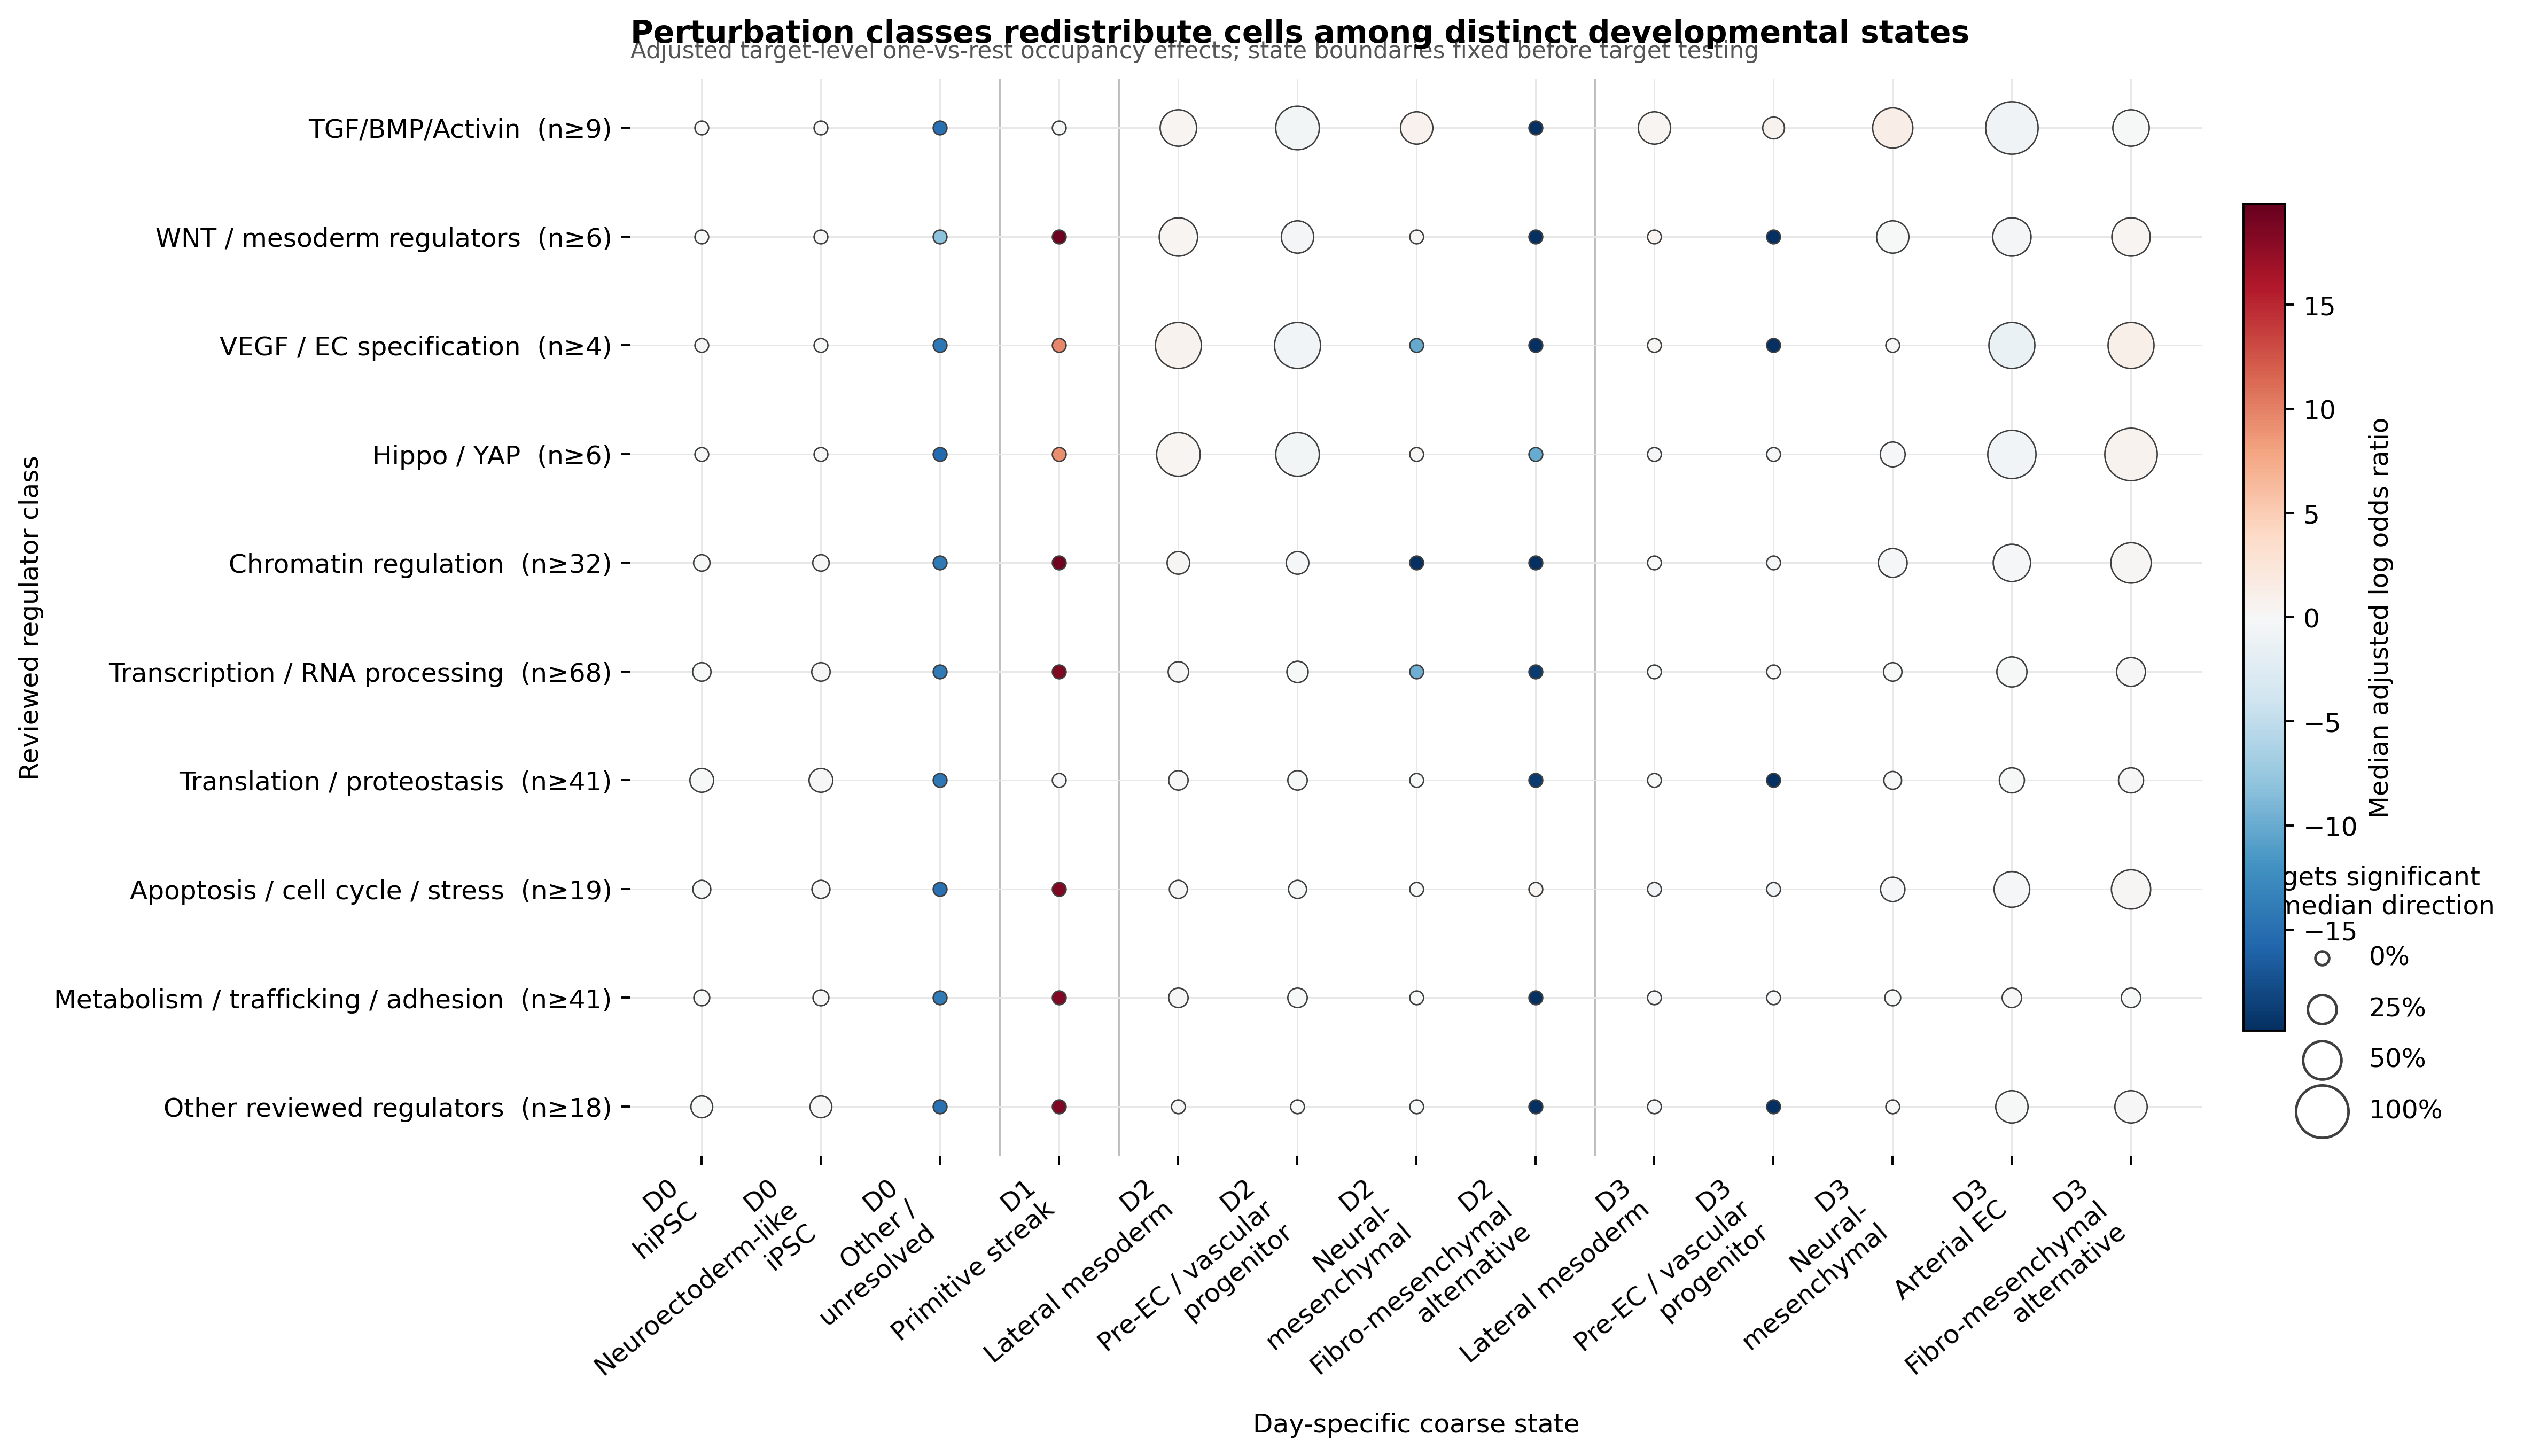

Supplementary target-level heatmap




In [9]:
main_png = RESULT_DIR / "Fig2_perturbation_class_state_occupancy.png"
heatmap_png = RESULT_DIR / "Fig2_target_state_occupancy_heatmap_supplementary.png"

assert main_png.exists(), main_png
assert heatmap_png.exists(), heatmap_png

print("Main panel")
display(Image(filename=str(main_png)))
print("Supplementary target-level heatmap")
display(Image(filename=str(heatmap_png)))


## 7. Final output audit and packaging

The SVG exports retain text as text (`svg.fonttype = none`) and PDFs use TrueType fonts (`pdf.fonttype = 42`) for Illustrator compatibility.

In [10]:
required_outputs = [
    "Fig2_perturbation_class_state_occupancy.svg",
    "Fig2_perturbation_class_state_occupancy.pdf",
    "Fig2_perturbation_class_state_occupancy.png",
    "Fig2_target_state_occupancy_heatmap_supplementary.svg",
    "Fig2_target_state_occupancy_heatmap_supplementary.pdf",
    "Fig2_target_state_occupancy_heatmap_supplementary.png",
    "target_state_occupancy_effects.tsv",
    "target_state_occupancy_by_replicate.tsv",
    "class_state_occupancy_summary.tsv",
    "class_membership.tsv",
    "state_definitions.tsv",
    "coverage_and_filtering.tsv",
    "draft_panel_legend.md",
    "methods_note.md",
]

missing = [name for name in required_outputs if not (RESULT_DIR / name).exists()]
print("Missing outputs:", missing)
assert not missing

# Check that SVG contains editable text nodes.
svg_text = (RESULT_DIR / "Fig2_perturbation_class_state_occupancy.svg").read_text(errors="ignore")
print("SVG contains <text> elements:", "<text" in svg_text)

zip_path = PACKAGE_DIR / "occupancy_analysis_results.zip"
if zip_path.exists():
    zip_path.unlink()
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in RESULT_DIR.rglob("*"):
        if p.is_file():
            zf.write(p, arcname=p.relative_to(RESULT_DIR))
print("Packaged results:", zip_path)


Missing outputs: []
SVG contains <text> elements: True
Packaged results: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_perturbation_class_occupancy_notebook_sherlock/occupancy_analysis_results.zip


## Interpretation and reporting caveats

- These are occupancy effects in pre-existing coarse states, not target→program effects.
- State boundaries are the existing author-defined Leiden labels and are not rediscovered from carriers.
- The primary coefficient is the adjusted target-level log odds ratio from a day-specific one-vs-rest logistic model.
- Class dots summarize fitted target-level estimates; class guides are not pooled into a single exposure.
- The legacy state labels are hard assignments, so a genuine soft-probability sensitivity analysis is not available from this object.
- The main figure should be described as an **author-defined coarse-state occupancy analysis**, not as a new control-defined clustering analysis.